# Telco Customer Churn Prediction

**Goal:** predict which customers of a telecom company are likely to cancel their service (churn),
so a retention team can contact the highest-risk customers first.

**Dataset:** [IBM Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) —
7,043 customers, 19 usable features, binary target `Churn`.

**Workflow**
1. Setup
2. Load & clean the data
3. Exploratory data analysis (EDA)
4. Train/test split (stratified; the test set is held out until the end)
5. Preprocessing pipeline (fit inside cross-validation folds only → no data leakage)
6. Train & tune 4 models with 5-fold stratified cross-validation
7. Select the final model by CV score; tune the decision threshold on out-of-fold predictions
8. Evaluate once on the held-out test set
9. Interpret the model
10. Save the model and predict on new customers

> **To run:** put `WA_Fn-UseC_-Telco-Customer-Churn.csv` in the same folder as this notebook
> (or in `data/raw/`), then *Run All*. Full run takes ~2–3 minutes.

## 1. Setup

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             make_scorer, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)

# ---- Configuration ----
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
TARGET, ID_COL = "Churn", "customerID"

NUMERIC_FEATURES = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
CATEGORICAL_FEATURES = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
                        "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                        "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
                        "PaperlessBilling", "PaymentMethod"]
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Find the dataset next to the notebook or in the usual project folders
CSV_NAME = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
candidates = [Path(CSV_NAME), Path("data/raw") / CSV_NAME, Path("../data/raw") / CSV_NAME, Path("data") / CSV_NAME]
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH is not None, f"Put {CSV_NAME} in the same folder as this notebook."

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
print("Data file:", DATA_PATH)

Data file: WA_Fn-UseC_-Telco-Customer-Churn.csv


### Plotting helpers
One consistent, colorblind-safe style: **Retained = blue**, **Churned = orange**, and each model keeps
the same color in every chart.

In [2]:
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
RETAINED, CHURNED = SERIES[0], SERIES[1]
NEUTRAL, INK, INK_2, GRID, SURFACE = "#8a8985", "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
MODEL_COLORS = {"Logistic Regression": "#1baf7a", "Random Forest": "#eda100",
                "Hist Gradient Boosting": "#6250d6"}
BLUE_SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#eef4fc", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 2,
})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")


def plot_churn_rate_by(df, columns, ncols=3):
    """Churn rate per category, one panel per feature; dashed line = overall churn rate."""
    overall = df[TARGET].mean()
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 2.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columns):
        rates = df.groupby(col, observed=True)[TARGET].mean().sort_values()
        ax.barh(rates.index.astype(str), rates.values, color=CHURNED, height=0.6)
        ax.axvline(overall, color=NEUTRAL, linestyle="--", linewidth=1)
        for i, v in enumerate(rates.values):
            ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9, color=INK_2)
        ax.set_xlim(0, max(0.75, rates.max() + 0.12))
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.grid(axis="y", visible=False)
        ax.set_title(col, fontsize=11)
    for ax in axes[len(columns):]:
        ax.set_visible(False)
    fig.suptitle(f"Churn rate by category (dashed line = overall rate {overall:.1%})",
                 x=0.01, ha="left", fontweight="bold", fontsize=13)
    fig.tight_layout()
    return fig


def plot_confusion_matrix(cm, title):
    fig, ax = plt.subplots(figsize=(4.4, 3.8))
    ax.imshow(cm, cmap=BLUE_SEQ)
    labels = ["Retained", "Churned"]
    ax.set_xticks([0, 1], labels); ax.set_yticks([0, 1], labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm.sum():.1%})", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() * 0.55 else INK, fontsize=11)
    ax.grid(False)
    ax.set_title(title)
    return fig

## 2. Load and inspect the raw data

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` is stored as text instead of a number. Let's find out why.

In [5]:
not_numeric = pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()
print("Rows where TotalCharges is not a number:", not_numeric.sum())
raw.loc[not_numeric, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Rows where TotalCharges is not a number: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


All 11 problem rows have `tenure == 0`: brand-new customers who haven't been billed yet, so the correct
value is **0**. This is a fixed rule that learns nothing from the data, so it causes no leakage and can be
applied before splitting. We also map `Churn` Yes/No → 1/0. `customerID` is an identifier and is never
used as a feature.

In [6]:
def clean(df):
    """Deterministic row-wise cleaning. Works with or without the Churn column."""
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df.loc[df["TotalCharges"].isna() & (df["tenure"] == 0), "TotalCharges"] = 0.0
    if TARGET in df.columns:
        df[TARGET] = df[TARGET].map({"Yes": 1, "No": 0}).astype(int)
    return df


df = clean(raw)
print("Missing values after cleaning:", int(df.isna().sum().sum()))
print("Duplicate customer IDs:", int(df[ID_COL].duplicated().sum()))
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

Missing values after cleaning: 0
Duplicate customer IDs: 0


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


## 3. Exploratory Data Analysis
### 3.1 Target distribution

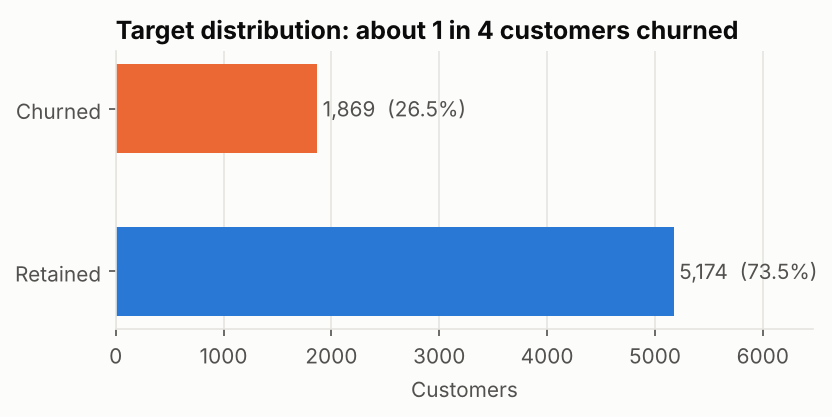

In [7]:
counts = df[TARGET].value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(["Retained", "Churned"], counts.values, color=[RETAINED, CHURNED], height=0.55)
for i, c in enumerate(counts.values):
    ax.text(c + 50, i, f"{c:,}  ({c / counts.sum():.1%})", va="center", color=INK_2)
ax.set_xlim(0, counts.max() * 1.25); ax.grid(axis="y", visible=False)
ax.set_xlabel("Customers"); ax.set_title("Target distribution: about 1 in 4 customers churned")
save(fig, "eda_target_distribution")
plt.show()

The classes are imbalanced (~26.5% churn), which drives several choices:
- **Accuracy is misleading** — predicting "no churn" for everyone already scores ~73.5%.
- Primary metric: **ROC-AUC**; we also report **PR-AUC, precision, recall and F1** for the churn class.
- **Stratified** split and CV, plus **class weights** in the models.

### 3.2 Numeric features vs churn

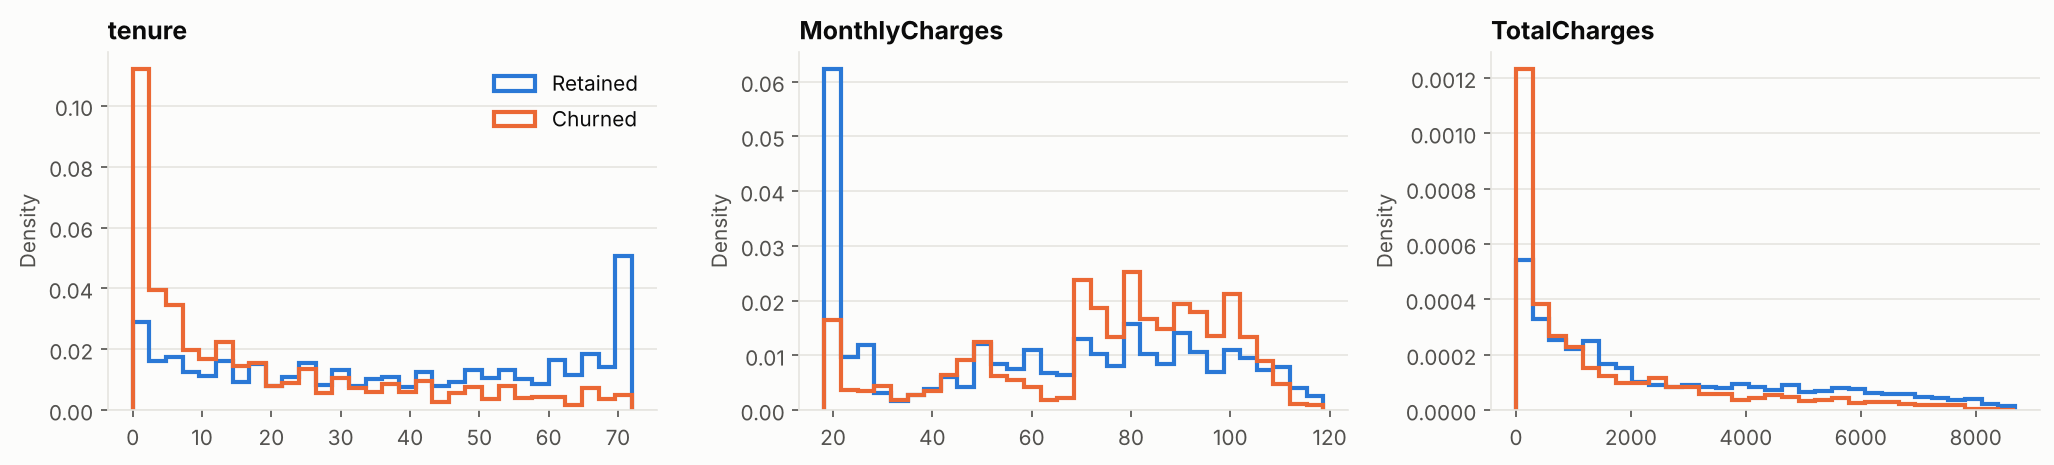

,tenure,MonthlyCharges,TotalCharges
Churn,,,
Retained,38.0,64.4,1679.5
Churned,10.0,79.6,703.6


In [8]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(13.8, 3.2))
for ax, col in zip(axes, num_cols):
    bins = np.histogram_bin_edges(df[col], bins=30)
    for label, color, name in [(0, RETAINED, "Retained"), (1, CHURNED, "Churned")]:
        ax.hist(df.loc[df[TARGET] == label, col], bins=bins, density=True,
                histtype="step", linewidth=2, color=color, label=name)
    ax.set_title(col); ax.set_ylabel("Density"); ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper right")
fig.tight_layout()
save(fig, "eda_numeric_by_churn")
plt.show()

df.groupby(TARGET)[num_cols].median().rename(index={0: "Retained", 1: "Churned"}).round(1)

- Churners are concentrated in the **first months of tenure**; long-tenure customers rarely leave.
- Churners tend to have **higher monthly charges**.
- `TotalCharges` is low for churners mainly because their tenure is short.

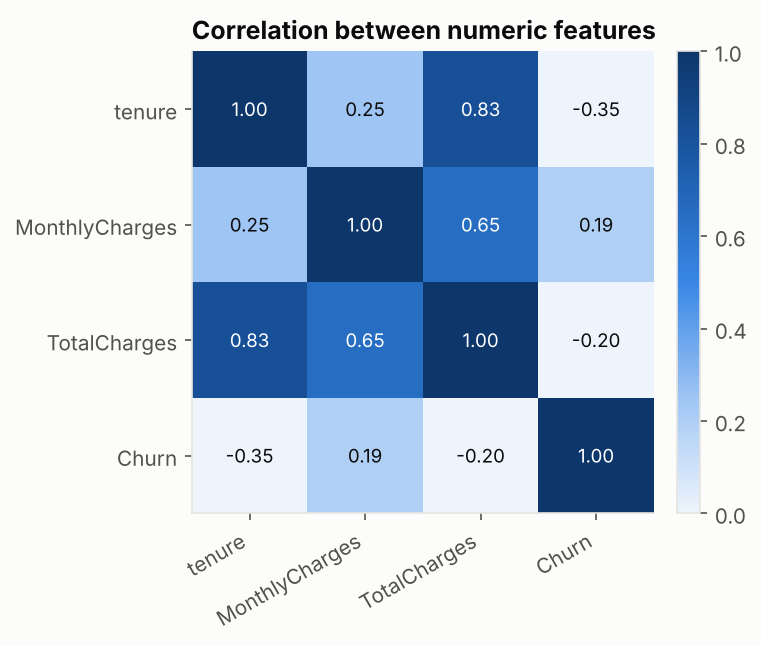

In [9]:
corr_cols = num_cols + [TARGET]
corr = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr.values, cmap=BLUE_SEQ, vmin=0, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=30, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.6 else INK, fontsize=9)
ax.grid(False); fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Correlation between numeric features")
save(fig, "eda_correlation")
plt.show()

`TotalCharges` is strongly correlated with `tenure` (0.83), since it is roughly tenure × monthly charge.
This redundancy is fine for tree models and regularized logistic regression, so we keep all three.

### 3.3 Churn rate by categorical feature

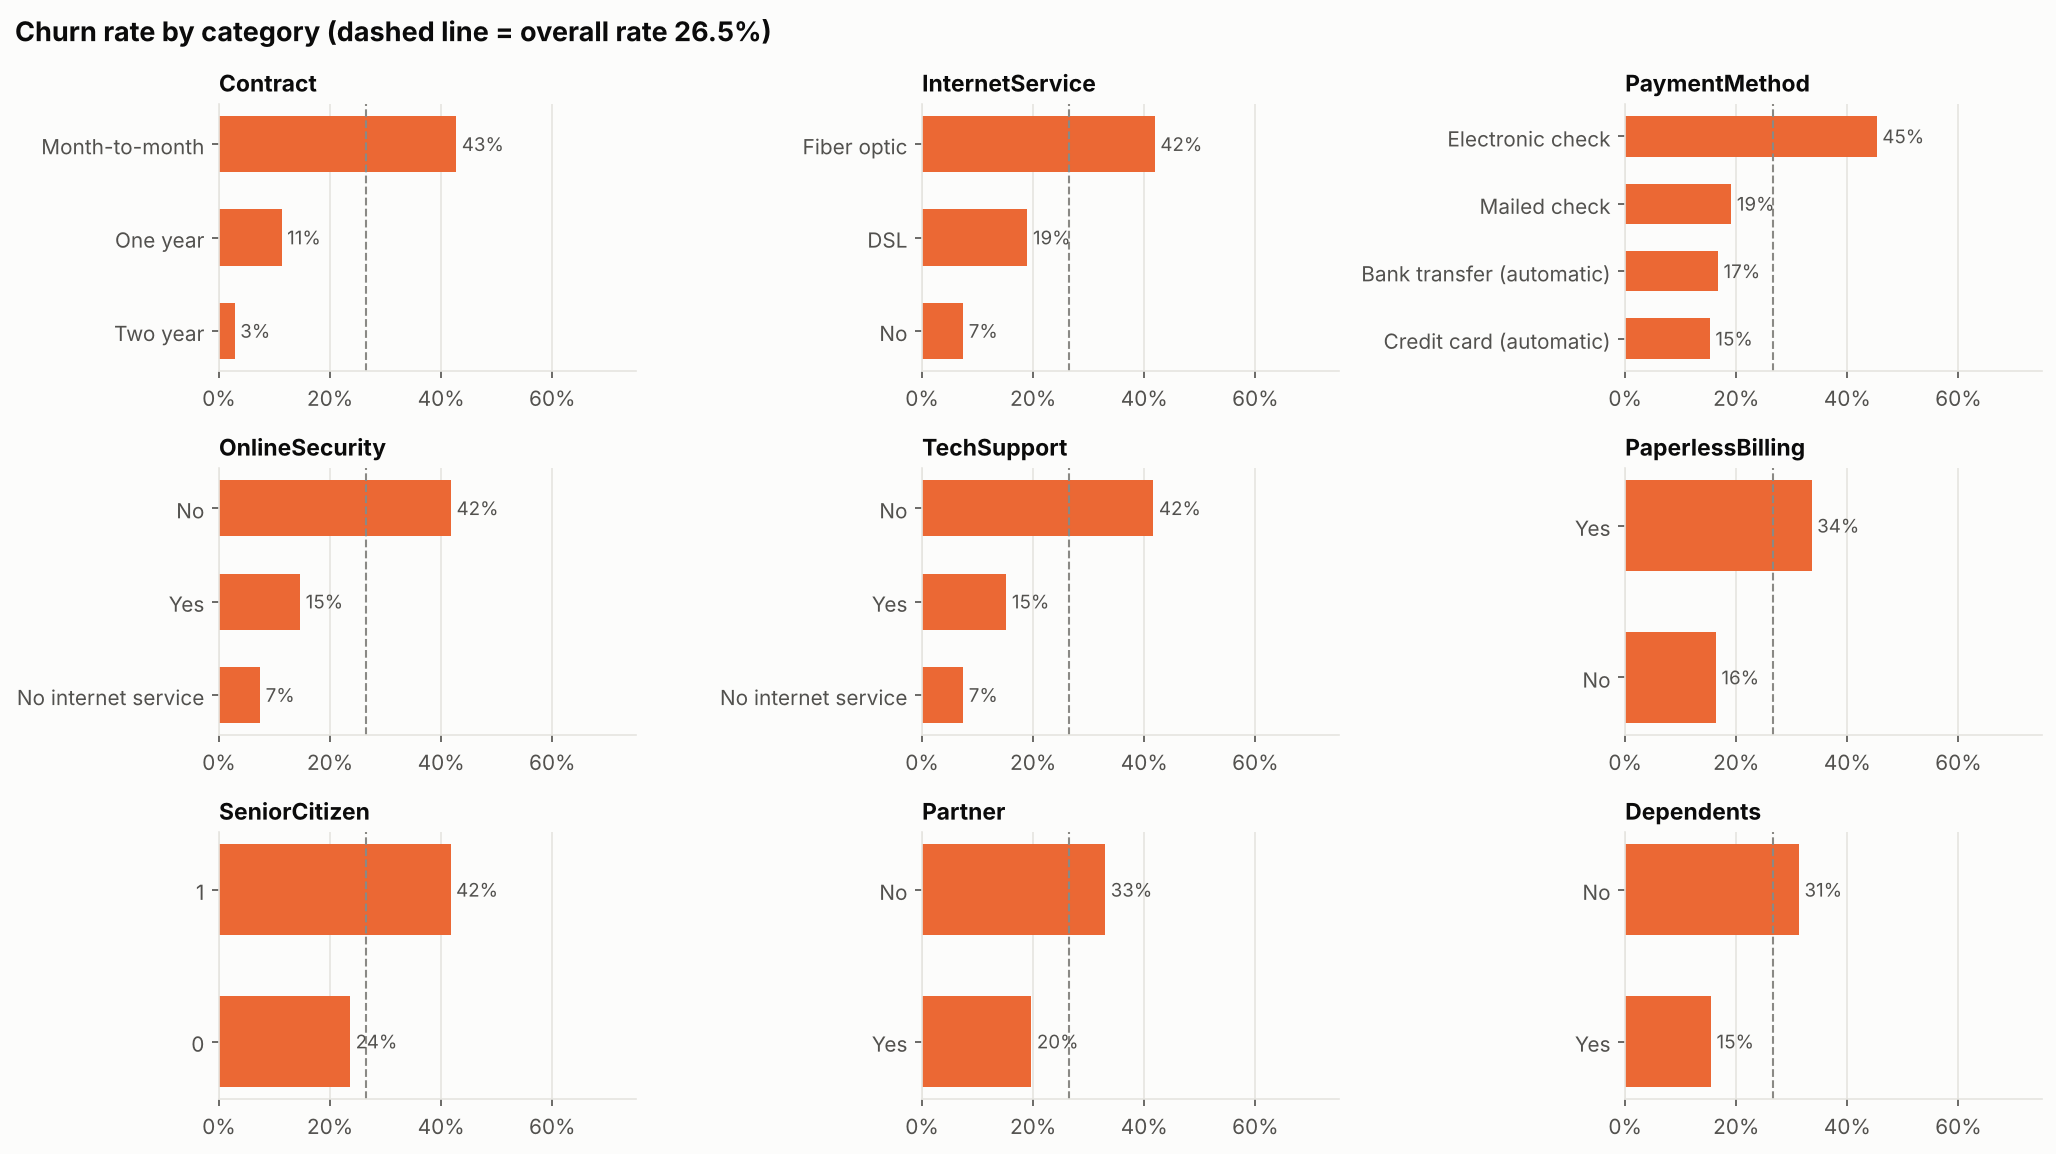

In [10]:
fig = plot_churn_rate_by(df, ["Contract", "InternetService", "PaymentMethod", "OnlineSecurity",
                              "TechSupport", "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents"])
save(fig, "eda_churn_rate_by_category")
plt.show()

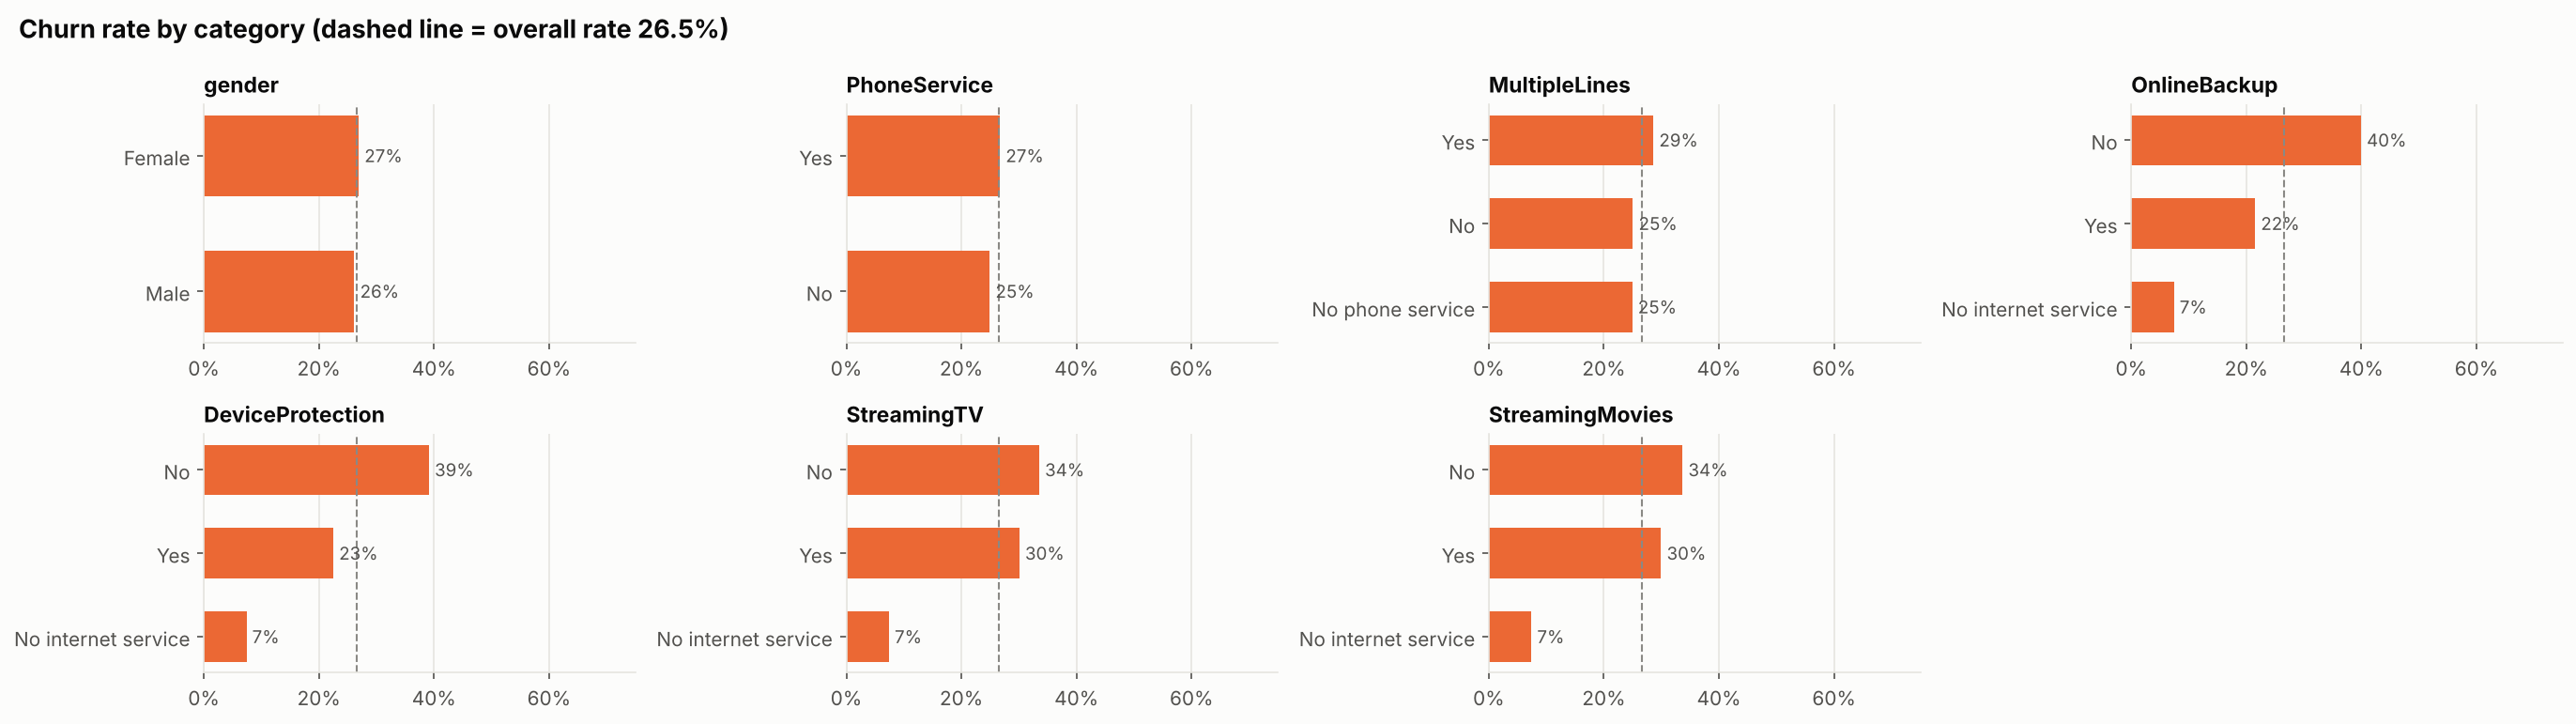

In [11]:
fig = plot_churn_rate_by(df, ["gender", "PhoneService", "MultipleLines", "OnlineBackup",
                              "DeviceProtection", "StreamingTV", "StreamingMovies"], ncols=4)
plt.show()

**Key EDA findings**
- **Contract type** is the strongest signal: month-to-month customers churn at ~43% vs ~11% (one-year) and ~3% (two-year).
- **Fiber optic** users churn more than DSL users; customers without internet churn least.
- **Electronic check** payers churn more than customers on automatic payments.
- Customers **without online security or tech support** churn more.
- **Senior citizens** and customers **without a partner or dependents** churn more.
- **Gender** and **phone service** show almost no difference in churn rate.

## 4. Train/test split
Stratified 80/20 split. The test set is **not touched** again until the final evaluation.

In [12]:
X, y = df[ALL_FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}, churn rate {y_train.mean():.3f}")
print(f"Test:  {X_test.shape}, churn rate {y_test.mean():.3f}")

Train: (5634, 19), churn rate 0.265
Test:  (1409, 19), churn rate 0.265


## 5. Preprocessing pipeline
Everything that **learns from data** (imputation values, scaling parameters, one-hot categories) lives in a
`ColumnTransformer` placed **inside** the model `Pipeline`. During cross-validation it is re-fit on each
training fold only, so validation and test rows never influence preprocessing.

In [13]:
def build_preprocessor():
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),   # safety net for missing values in new data
        ("scaler", StandardScaler()),                    # needed by Logistic Regression
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([("num", numeric, NUMERIC_FEATURES),
                              ("cat", categorical, CATEGORICAL_FEATURES)],
                             verbose_feature_names_out=False)


def build_pipeline(estimator):
    return Pipeline([("preprocess", build_preprocessor()), ("clf", estimator)])


n_out = build_preprocessor().fit(X_train).transform(X_train.head()).shape[1]
print(f"{len(ALL_FEATURES)} input columns -> {n_out} model features after one-hot encoding")

19 input columns -> 45 model features after one-hot encoding


## 6. Model training and hyper-parameter tuning
| Model | Why |
|---|---|
| Dummy (predicts class prior) | Baseline every real model must beat |
| Logistic Regression | Simple, interpretable linear model |
| Random Forest | Bagged trees, captures non-linearities and interactions |
| Hist Gradient Boosting | Boosted trees, usually strongest on tabular data |

Class imbalance is handled with **class weights** (no synthetic rows, nothing to leak).
Each model is tuned with `GridSearchCV` using **5-fold stratified CV on the training set**, optimizing ROC-AUC.

In [14]:
candidates = {
    "Dummy (baseline)": (DummyClassifier(strategy="prior"), {}),
    "Logistic Regression": (
        LogisticRegression(max_iter=5000, class_weight="balanced"),
        {"clf__C": [0.01, 0.1, 1.0, 10.0, 100.0]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                               random_state=RANDOM_STATE, n_jobs=1),
        {"clf__max_depth": [4, 6, 8, 12], "clf__min_samples_leaf": [5, 10, 20],
         "clf__max_features": ["sqrt", 0.5]},
    ),
    "Hist Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", max_iter=200,
                                       early_stopping=False, random_state=RANDOM_STATE),
        {"clf__learning_rate": [0.03, 0.1], "clf__max_leaf_nodes": [4, 7, 15],
         "clf__min_samples_leaf": [20, 50], "clf__l2_regularization": [1.0, 5.0]},
    ),
}

scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "f1": make_scorer(f1_score, zero_division=0),
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),  # dummy never predicts churn
}
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

searches, rows = {}, []
for name, (estimator, grid) in candidates.items():
    start = time.time()
    search = GridSearchCV(build_pipeline(estimator), grid, scoring=scoring,
                          refit="roc_auc", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
    i = search.best_index_
    row = {"model": name}
    for m in scoring:
        row[f"cv_{m}"] = search.cv_results_[f"mean_test_{m}"][i]
    row["cv_roc_auc_std"] = search.cv_results_["std_test_roc_auc"][i]
    row["best_params"] = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    rows.append(row)
    print(f"{name:<24} CV ROC-AUC = {row['cv_roc_auc']:.4f} ± {row['cv_roc_auc_std']:.4f}  "
          f"({time.time() - start:.0f}s)")

cv_table = pd.DataFrame(rows).set_index("model").sort_values("cv_roc_auc", ascending=False)

Dummy (baseline)         CV ROC-AUC = 0.5000 ± 0.0000  (1s)
Logistic Regression      CV ROC-AUC = 0.8462 ± 0.0127  (1s)
Random Forest            CV ROC-AUC = 0.8482 ± 0.0104  (94s)
Hist Gradient Boosting   CV ROC-AUC = 0.8494 ± 0.0119  (31s)


## 7. Model comparison and selection

In [15]:
cv_table.round(4)

,cv_roc_auc,cv_pr_auc,cv_f1,cv_recall,cv_precision,cv_roc_auc_std,best_params
model,,,,,,,
Hist Gradient Boosting,0.8494,0.6679,0.6312,0.8054,0.5192,0.0119,"{'l2_regularization': 5.0, 'learning_rate': 0.03, 'max_leaf_nodes': 7, 'min_samples_leaf': 50}"
Random Forest,0.8482,0.6645,0.6322,0.7826,0.5305,0.0104,"{'max_depth': 6, 'max_features': 0.5, 'min_samples_leaf': 20}"
Logistic Regression,0.8462,0.6589,0.6274,0.8000,0.5162,0.0127,{'C': 10.0}
Dummy (baseline),0.5000,0.2654,0.0000,0.0000,0.0000,0.0000,{}


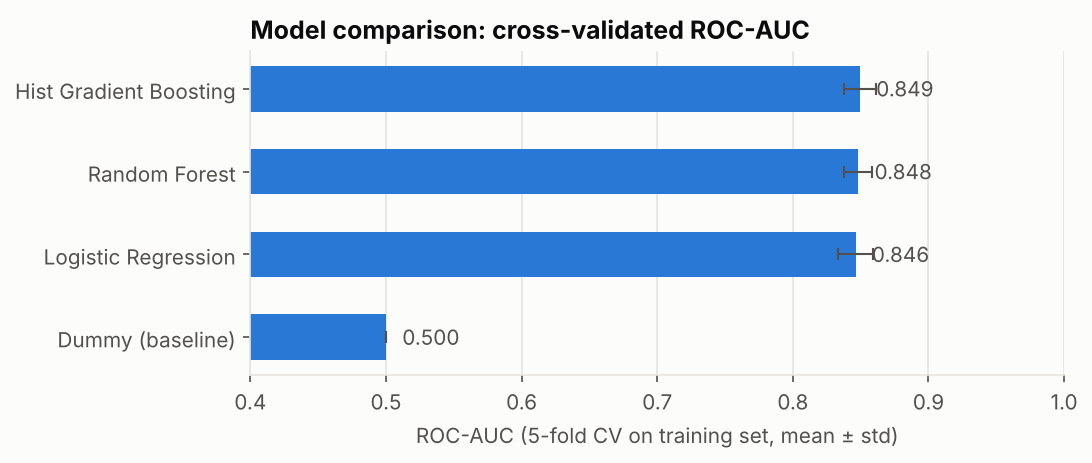

In [16]:
t = cv_table.sort_values("cv_roc_auc")
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(t.index, t["cv_roc_auc"], xerr=t["cv_roc_auc_std"], color=RETAINED, height=0.55,
        error_kw={"ecolor": INK_2, "capsize": 3, "linewidth": 1})
for i, v in enumerate(t["cv_roc_auc"]):
    ax.text(v + 0.012, i, f"{v:.3f}", va="center", color=INK_2)
ax.set_xlim(0.4, 1.0); ax.grid(axis="y", visible=False)
ax.set_xlabel("ROC-AUC (5-fold CV on training set, mean ± std)")
ax.set_title("Model comparison: cross-validated ROC-AUC")
save(fig, "cv_model_comparison")
plt.show()

The final model is chosen by **mean CV ROC-AUC** — never by test score, otherwise the test score would no
longer be an unbiased estimate.

**Decision threshold:** the default 0.5 is arbitrary. We choose the threshold that maximizes F1 using
**out-of-fold** predictions on the training set (`cross_val_predict`) — again without looking at the test set.

Selected model: Hist Gradient Boosting
Best hyper-parameters: {'l2_regularization': 5.0, 'learning_rate': 0.03, 'max_leaf_nodes': 7, 'min_samples_leaf': 50}
F1-optimal threshold (out-of-fold, training set): 0.574


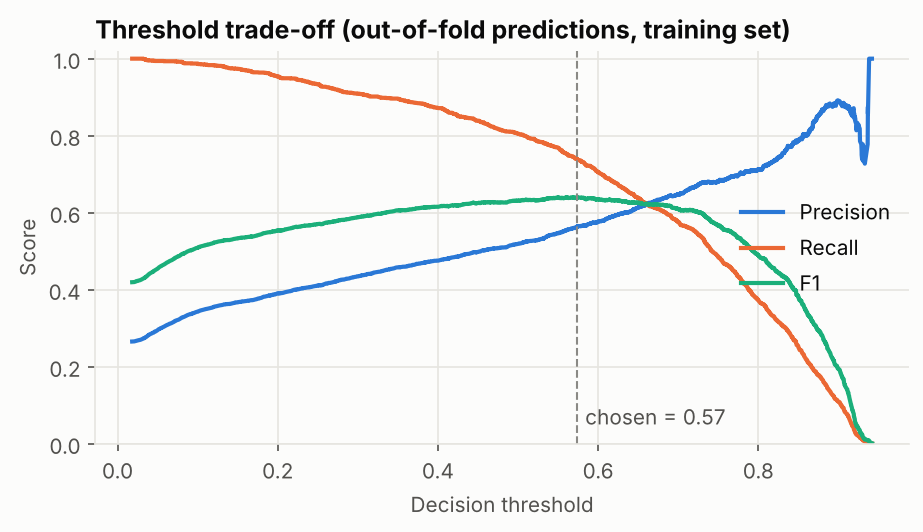

In [17]:
best_name = cv_table.index[0]
best_model = searches[best_name].best_estimator_
print("Selected model:", best_name)
print("Best hyper-parameters:", cv_table.loc[best_name, "best_params"])

oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
threshold = float(thr[np.argmax(f1)])
print(f"F1-optimal threshold (out-of-fold, training set): {threshold:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(thr, prec[:-1], color=SERIES[0], label="Precision")
ax.plot(thr, rec[:-1], color=SERIES[1], label="Recall")
ax.plot(thr, f1, color=SERIES[2], label="F1")
ax.axvline(threshold, color=NEUTRAL, linestyle="--", linewidth=1)
ax.text(threshold + 0.01, 0.05, f"chosen = {threshold:.2f}", color=INK_2)
ax.set(xlabel="Decision threshold", ylabel="Score", ylim=(0, 1.02),
       title="Threshold trade-off (out-of-fold predictions, training set)")
ax.legend(loc="center right")
save(fig, "threshold_tradeoff")
plt.show()

## 8. Final evaluation on the held-out test set
Every tuned model is scored once on the test set for transparency (threshold 0.5). The selection above
was already made, so these numbers do not influence any decision.

In [18]:
def compute_metrics(y_true, proba, threshold=0.5):
    y_pred = (proba >= threshold).astype(int)
    return {"roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba),
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)}


test_proba = {name: s.best_estimator_.predict_proba(X_test)[:, 1] for name, s in searches.items()}
test_table = pd.DataFrame({name: compute_metrics(y_test, p) for name, p in test_proba.items()}).T
test_table.loc[cv_table.index].round(4)

,roc_auc,pr_auc,accuracy,precision,recall,f1
model,,,,,,
Hist Gradient Boosting,0.8485,0.6636,0.7516,0.5208,0.8048,0.6324
Random Forest,0.8462,0.6577,0.7544,0.5250,0.7861,0.6296
Logistic Regression,0.8406,0.6269,0.7395,0.5060,0.7834,0.6149
Dummy (baseline),0.5000,0.2654,0.7346,0.0000,0.0000,0.0000


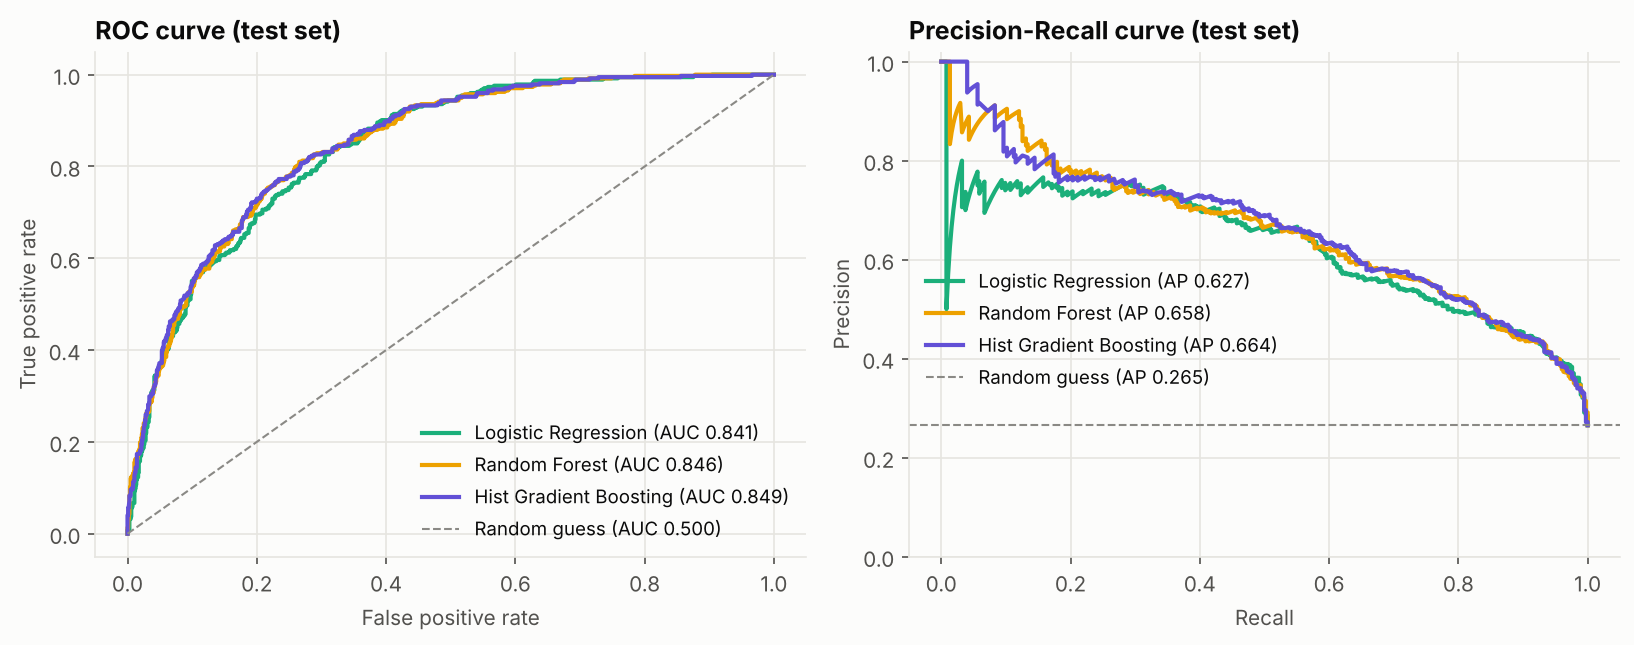

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
for name, color in MODEL_COLORS.items():
    p = test_proba[name]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax1.plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax2.plot(rc, pr, color=color, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
ax1.plot([0, 1], [0, 1], color=NEUTRAL, linestyle="--", linewidth=1, label="Random guess (AUC 0.500)")
ax2.axhline(y_test.mean(), color=NEUTRAL, linestyle="--", linewidth=1,
            label=f"Random guess (AP {y_test.mean():.3f})")
ax1.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test set)")
ax2.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve (test set)", ylim=(0, 1.02))
ax1.legend(loc="lower right", fontsize=9)
ax2.legend(loc="lower left", bbox_to_anchor=(0, 0.3), fontsize=9)
fig.tight_layout()
save(fig, "roc_pr_curves")
plt.show()

In [20]:
best_proba = test_proba[best_name]
final = pd.DataFrame({"threshold 0.50": compute_metrics(y_test, best_proba, 0.5),
                      f"tuned threshold {threshold:.2f}": compute_metrics(y_test, best_proba, threshold)}).T

top20 = np.argsort(-best_proba)[: int(np.ceil(0.2 * len(best_proba)))]
captured = y_test.values[top20].sum() / y_test.sum()
print(f"Final model: {best_name}")
print(f"Contacting only the 20% riskiest test customers would reach {captured:.1%} of all churners.")
final.round(4)

Final model: Hist Gradient Boosting
Contacting only the 20% riskiest test customers would reach 51.3% of all churners.


,roc_auc,pr_auc,accuracy,precision,recall,f1
threshold 0.50,0.8485,0.6636,0.7516,0.5208,0.8048,0.6324
tuned threshold 0.57,0.8485,0.6636,0.7771,0.5605,0.7433,0.6391


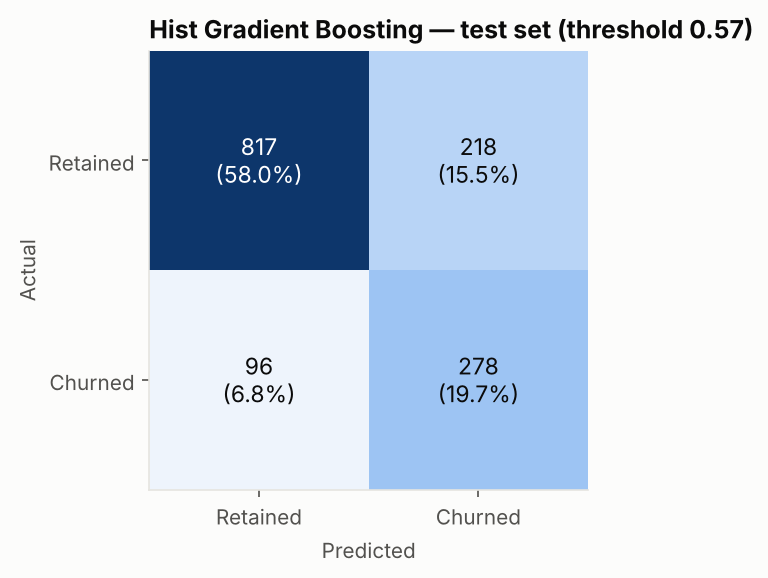

In [21]:
cm = confusion_matrix(y_test, (best_proba >= threshold).astype(int))
fig = plot_confusion_matrix(cm, f"{best_name} — test set (threshold {threshold:.2f})")
save(fig, "confusion_matrix")
plt.show()

## 9. Model interpretation — permutation importance
Each original column is randomly shuffled on the test set and we measure how much ROC-AUC drops.
It works for any model type and on the original columns (before one-hot encoding).

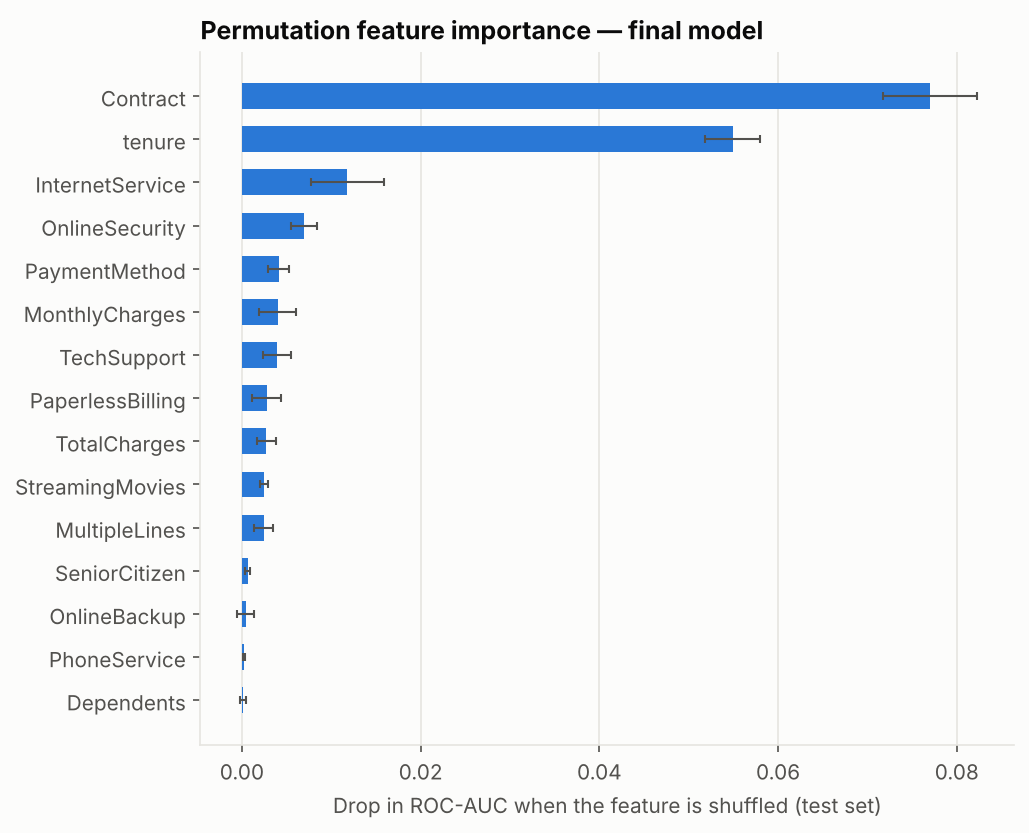

,importance_mean,importance_std
Contract,0.0770,0.0053
tenure,0.0549,0.0031
InternetService,0.0118,0.0041
OnlineSecurity,0.0070,0.0015
PaymentMethod,0.0041,0.0012
MonthlyCharges,0.0040,0.0021
TechSupport,0.0039,0.0016
PaperlessBilling,0.0028,0.0016
TotalCharges,0.0027,0.0010
StreamingMovies,0.0025,0.0005


In [22]:
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"importance_mean": perm.importances_mean,
                            "importance_std": perm.importances_std}, index=X_test.columns)
              .sort_values("importance_mean", ascending=False))

t = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 0.32 * len(t) + 1.2))
ax.barh(t.index, t["importance_mean"], xerr=t["importance_std"], color=RETAINED, height=0.6,
        error_kw={"ecolor": INK_2, "capsize": 2, "linewidth": 1})
ax.grid(axis="y", visible=False)
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled (test set)")
ax.set_title("Permutation feature importance — final model")
save(fig, "feature_importance")
plt.show()

importance.head(10).round(4)

## 10. Save the model and predict on new customers
The whole pipeline (preprocessing + model) and the chosen threshold are saved together, so raw customer
records can be scored directly.

In [23]:
joblib.dump({"pipeline": best_model, "threshold": threshold, "model_name": best_name}, "churn_model.joblib")


def predict_churn(raw_customers, model_path="churn_model.joblib"):
    bundle = joblib.load(model_path)
    data = clean(raw_customers)
    proba = bundle["pipeline"].predict_proba(data[ALL_FEATURES])[:, 1]
    return pd.DataFrame({ID_COL: data[ID_COL].values,
                         "churn_probability": proba.round(4),
                         "churn_prediction": (proba >= bundle["threshold"]).astype(int)})


new_customers = raw.drop(columns=[TARGET]).sample(5, random_state=0)
predict_churn(new_customers)

,customerID,churn_probability,churn_prediction
0,6296-DDOOR,0.2287,0
1,3680-CTHUH,0.3946,0
2,4931-TRZWN,0.5341,0
3,8559-WNQZS,0.1016,0
4,3537-HPKQT,0.4698,0


## 11. Conclusions

**Results** (5-fold CV on the training set; held-out test set of 1,409 customers):

| Model | CV ROC-AUC | Test ROC-AUC | Test PR-AUC |
|---|---|---|---|
| **Hist Gradient Boosting (selected)** | 0.849 ± 0.012 | 0.849 | 0.664 |
| Random Forest | 0.848 ± 0.010 | 0.846 | 0.658 |
| Logistic Regression | 0.846 ± 0.013 | 0.841 | 0.627 |
| Dummy baseline | 0.500 | 0.500 | 0.265 |

With the tuned threshold (0.57), the final model reaches **recall 0.74, precision 0.56, F1 0.64** on the
test set, and the 20% highest-risk customers contain **51%** of all churners.

**Takeaways**
- All three real models clearly beat the baseline but are **statistically very close** (differences smaller
  than one CV standard deviation). Gradient Boosting was selected by the pre-defined rule; Logistic Regression
  is a reasonable alternative when interpretability matters most.
- Test scores closely match CV scores, which suggests the evaluation is not over-optimistic.
- The strongest churn drivers are **contract type** and **tenure**, followed by internet service type and
  the presence of online security / tech support.

**Limitations & next steps**
- Single snapshot dataset: a production model should be validated on a later time period (out-of-time).
- Class-weighted models give uncalibrated probabilities; add `CalibratedClassifierCV` if exact probabilities are needed.
- Choose the threshold from real business costs (retention offer cost vs. lost customer value).
- Add SHAP for per-customer explanations; serve the model behind a small API.